# TabPFN + SHAP — Binary Classification in the Low-Data Regime

A compact, end-to-end notebook for a small tabular dataset (~100 features, ~1k–10k rows):

1. Fit **TabPFN-2** — a foundation model that solves the task in a single forward pass (no hyperparameter tuning, strong on small data).
2. Evaluate it honestly (ROC-AUC, PR-AUC, cross-validation).
3. Explain it with **SHAP** — both *global* feature importance and *per-prediction* feature contributions.

> **License note:** TabPFN-2 open weights are for research / internal evaluation only — not commercial or production use. For production you need Prior Labs' Enterprise License (sales@priorlabs.ai).


## 2. Imports

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, RocCurveDisplay,
)
from tabpfn import TabPFNClassifier

RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

np.random.seed(RANDOM_STATE)

Using device: cuda


## 3. Load your data

Replace the demo block with your own `X` (features) and `y` (binary 0/1 target).
Keep `X` as a **pandas DataFrame** — the column names flow straight through into every SHAP plot.

TabPFN-2 targets exactly your regime: structured tabular data, designed for small-to-medium sample sizes, up to ~2000 features.


In [8]:
# --- DEMO DATA -------------------------------------------------------------
# Swap this block for your own DataFrame `X` and binary Series `y`.
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X = data.data            # (569, 30) -> replace with your ~100-feature frame
y = data.target          # binary 0/1
# ---------------------------------------------------------------------------

assert isinstance(X, pd.DataFrame), "Keep X as a DataFrame so feature names reach SHAP."
assert set(pd.unique(y)) <= {0, 1}, "Target must be binary 0/1."
print(f"Samples: {X.shape[0]:,} | Features: {X.shape[1]} | Positive rate: {float(np.mean(y)):.1%}")

Samples: 569 | Features: 30 | Positive rate: 62.7%


## 4. Train / test split

Stratify to preserve the class balance — it matters when data is scarce.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)}   Test: {len(X_test)}")

Train: 426   Test: 143


## 5. Fit TabPFN

No tuning loop — TabPFN learns in-context from the training rows during a single forward pass.


In [10]:
ckpt_path = "/projects/standard/srivasta/shared/truro/tabpfn_weights/tabpfn-v2-classifier.ckpt"
print(f"Using checkpoint: {ckpt_path}")

Using checkpoint: /projects/standard/srivasta/shared/truro/tabpfn_weights/tabpfn-v2-classifier.ckpt


In [11]:
clf = TabPFNClassifier(
    model_path=ckpt_path,  # use the locally downloaded checkpoint
    device=DEVICE,
    n_estimators=4,             # internal ensemble size; more = better/slower
)
clf.fit(X_train, y_train)

,n_estimators,4
,categorical_features_indices,None
,softmax_temperature,0.9
,balance_probabilities,False
,average_before_softmax,False
,model_path,'/projects/standard/sri...bpfn-v2-classifier.ckpt'
,device,'cuda'
,ignore_pretraining_limits,False
,inference_precision,'auto'
,fit_mode,'fit_preprocessors'
,memory_saving_mode,'auto'


## 6. Evaluate

Accuracy : 0.965
ROC-AUC  : 0.996
PR-AUC   : 0.998

              precision    recall  f1-score   support

           0      0.944     0.962     0.953        53
           1      0.978     0.967     0.972        90

    accuracy                          0.965       143
   macro avg      0.961     0.964     0.963       143
weighted avg      0.965     0.965     0.965       143



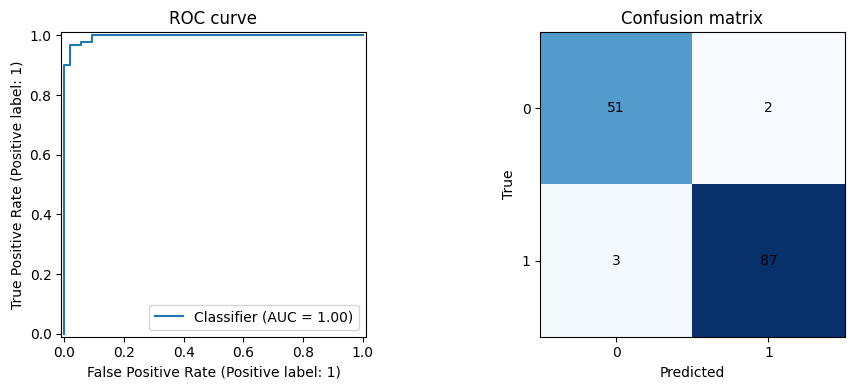

In [12]:
proba = clf.predict_proba(X_test)[:, 1]      # probability of the positive class
pred = (proba >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, proba):.3f}")
print(f"PR-AUC   : {average_precision_score(y_test, proba):.3f}")
print()
print(classification_report(y_test, pred, digits=3))

cm = confusion_matrix(y_test, pred)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax1)
ax1.set_title("ROC curve")
ax2.imshow(cm, cmap="Blues")
ax2.set(title="Confusion matrix", xlabel="Predicted", ylabel="True",
        xticks=[0, 1], yticks=[0, 1])
for (i, j), v in np.ndenumerate(cm):
    ax2.text(j, i, v, ha="center", va="center")
plt.tight_layout(); plt.show()

### (Optional) Cross-validated AUC

With only a few hundred rows, a single split is noisy. A stratified 5-fold gives a more honest estimate.


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(TabPFNClassifier(model_path=ckpt_path, device=DEVICE, n_estimators=4), X, y, cv=cv, scoring="roc_auc")
print(f"5-fold ROC-AUC: {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")

5-fold ROC-AUC: 0.997 +/- 0.005


## 7. Explain with SHAP

TabPFN has no internal tree/linear structure for SHAP to exploit, so we treat it as a **black box** and explain its `predict_proba` with a model-agnostic explainer.

Two design choices keep this fast and readable:

- **Explain only the positive-class probability** → every plot is 1-D and easy to interpret.
- **Use a small background sample** → each SHAP evaluation re-runs TabPFN's forward pass, so cost scales with `len(background) x n_features x n_explained_rows`. Keep it lean; scale up on a GPU.


In [15]:
feature_names = list(X_train.columns)

def positive_proba(data):
    """P(class = 1). SHAP feeds numpy arrays, so rebuild the frame to keep feature names aligned."""
    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data, columns=feature_names)
    return clf.predict_proba(data)[:, 1]

# Background = a small, representative summary of the training data (the SHAP baseline).
background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)

explainer = shap.Explainer(positive_proba, background)   # auto-selects a Permutation explainer

In [16]:
# Explain a subset of the test set. Bump this up if you have GPU time to spare.
X_explain = X_test.iloc[:30].copy()

# For >250 features, pass e.g. max_evals=2 * X_explain.shape[1] + 1 to satisfy the permutation budget.
shap_values = explainer(X_explain)

PermutationExplainer explainer: 31it [02:39,  5.30s/it]                        


### Global — which features drive predictions across the cohort

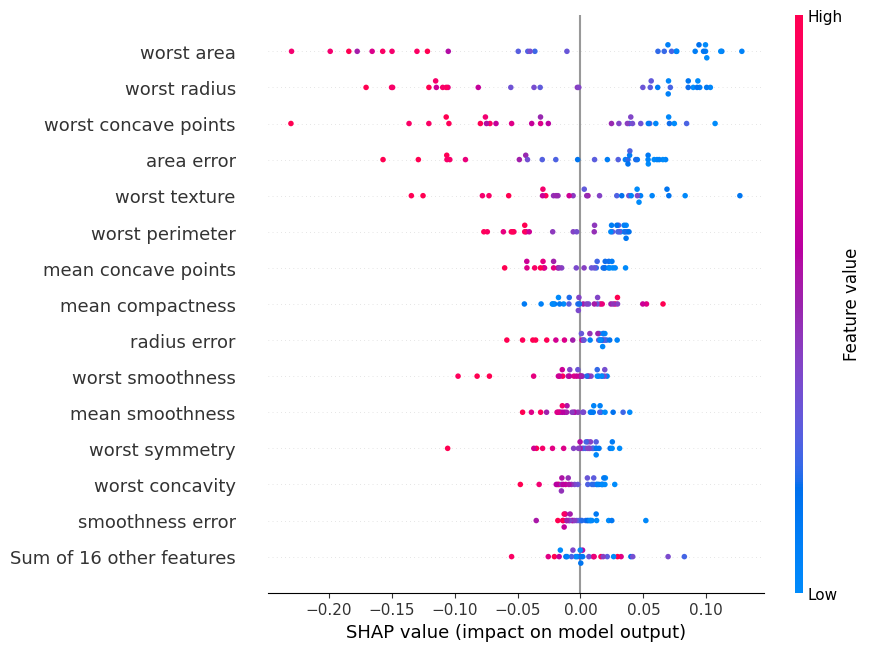

In [17]:
shap.plots.beeswarm(shap_values, max_display=15)

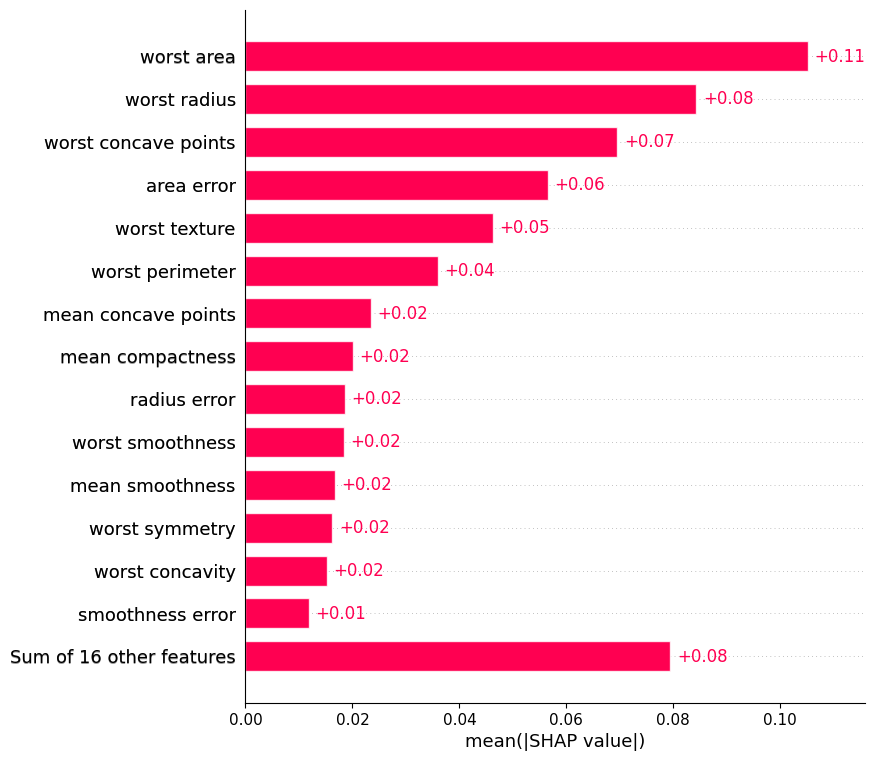

In [18]:
shap.plots.bar(shap_values, max_display=15)

### Local — every feature's contribution for a single prediction

The waterfall starts at the average model output (`E[f(x)]`) and shows how each feature pushes the
predicted probability up (toward class 1) or down (toward class 0) for that one row.


Row 0: predicted P(class=1) = 0.998  |  true label = 1


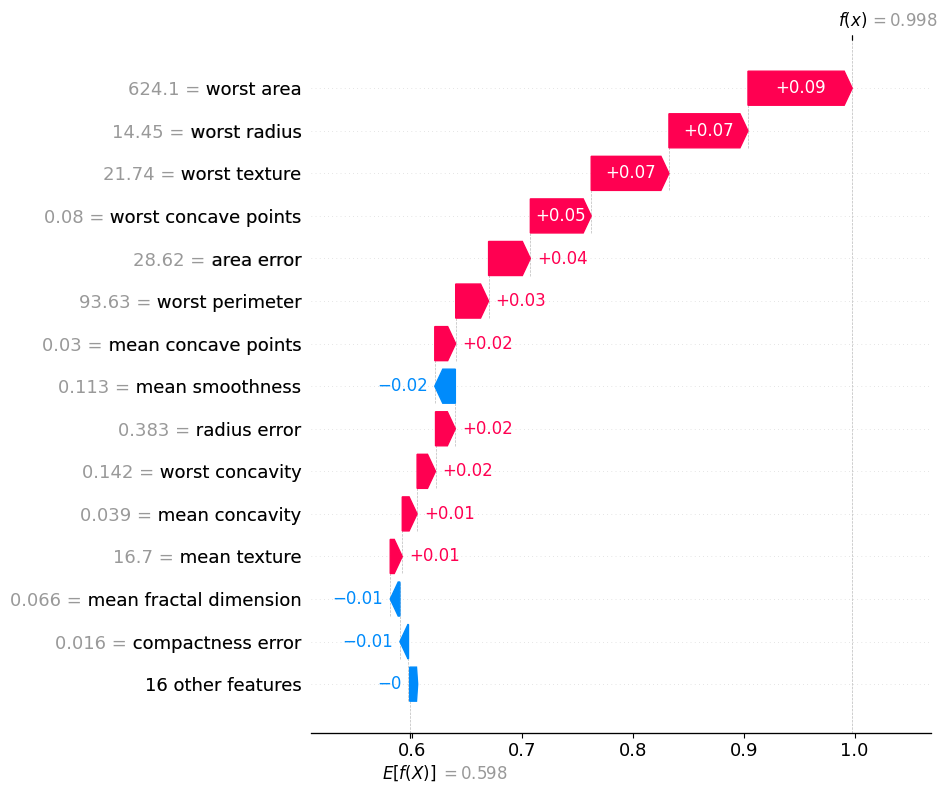

In [19]:
def explain_one(i: int):
    """Per-feature contributions for explained row i."""
    p = positive_proba(X_explain.iloc[[i]])[0]
    print(f"Row {i}: predicted P(class=1) = {p:.3f}  |  true label = {int(y_test.iloc[i])}")
    shap.plots.waterfall(shap_values[i], max_display=15)

explain_one(0)

Row 26: predicted P(class=1) = 1.000  |  true label = 1


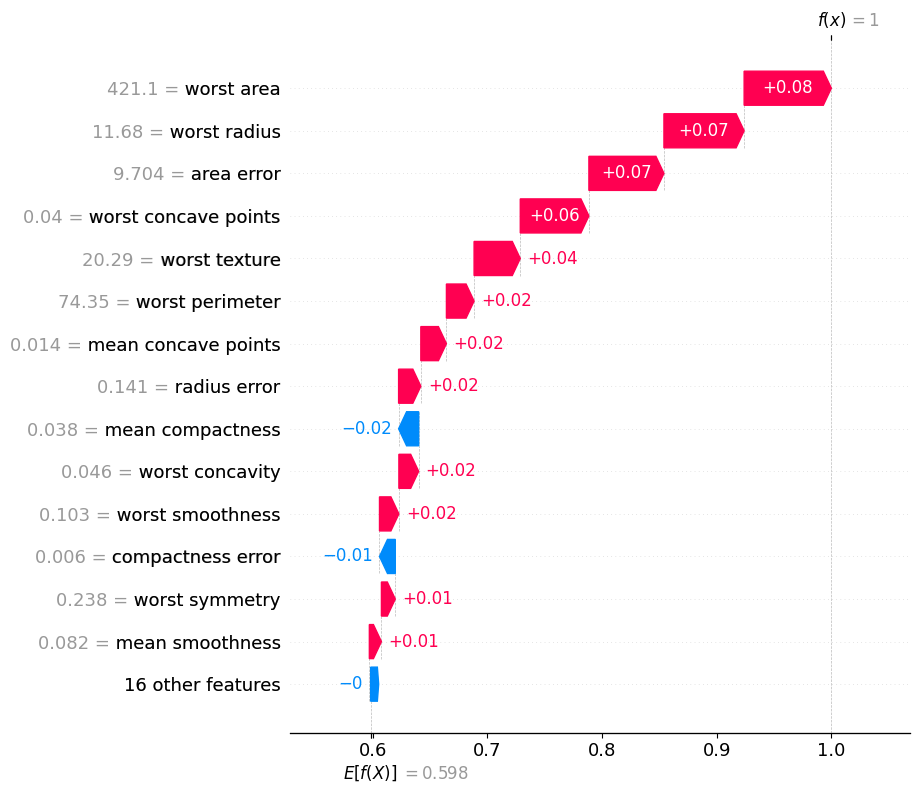

In [20]:
# Inspect the most confident positive prediction in the explained set
probs_explained = positive_proba(X_explain)
explain_one(int(np.argmax(probs_explained)))

### Dependence — how a feature's value relates to its impact

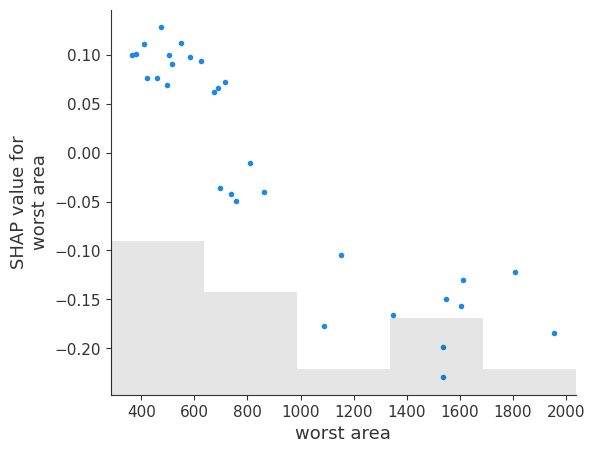

In [21]:
top_feature = X_explain.columns[np.argsort(-np.abs(shap_values.values).mean(0))[0]]
shap.plots.scatter(shap_values[:, top_feature])

## Notes & tuning

- **Speed:** SHAP calls `predict_proba` many times, and each call re-runs TabPFN's in-context forward pass. A GPU (`device="cuda"`) is dramatically faster. On CPU, keep `background` (~50–100) and `X_explain` (~30) small.
- **Accuracy of explanations:** more `max_evals` and a larger `background` reduce SHAP noise at the cost of runtime.
- **Feature count:** the permutation explainer needs `max_evals >= 2 * n_features + 1`. Set it explicitly if you go past ~250 features.
- **Calibration:** TabPFN is usually well-calibrated, but if you act on the probabilities, sanity-check with a reliability curve.
- **Binary checkpoint:** for a pure binary task you can A/B the specialised `..._binary.ckpt` against the default and keep whichever scores better.
